## Part 2: Single Stock Analysis Notebook

### 2.1 Parameters

In [1]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = None

In [2]:
# Parameters
ticker = "AAPL"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/wangyisu/Desktop/Documents/pre-courses/Python for Financial Engineers/UCB-MFE-python-preprogram-2026-winter/Lectures/Lecture 4/data/data.db"


In [3]:
# Use the existing Lecture 4 database unless a path is supplied as a parameter.
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
db_path = Path(db_path) if db_path else repo_root / "Lectures" / "Lecture 4" / "data" / "data.db"
if not db_path.is_file():
    raise FileNotFoundError(f"Database not found: {db_path}")
print("Database:", db_path)

Database: /Users/wangyisu/Desktop/Documents/pre-courses/Python for Financial Engineers/UCB-MFE-python-preprogram-2026-winter/Lectures/Lecture 4/data/data.db


### 2.2 Data Loading

In [4]:
# Read the cleaned table for the requested stock and dates.
with sqlite3.connect(db_path.resolve().as_uri() + "?mode=ro", uri=True) as conn:
    stock = pd.read_sql_query(
        """SELECT * FROM ohlc_hw_cleaned
           WHERE ticker = ? AND ts BETWEEN ? AND ?
           ORDER BY ts""",
        conn, params=(ticker, start_date, end_date), parse_dates=["ts"]
    )
print(f"{ticker} from {start_date} to {end_date}: {len(stock)} trading days")
if stock.empty:
    print("No observations in the requested range.")
else:
    print("Actual dates:", stock["ts"].min().date(), "to", stock["ts"].max().date())
    display(stock.head())
    display(stock.tail())
    if len(stock) < 21:
        print("Insufficient history for 20 daily returns; at least 21 prices are needed.")

AAPL from 2024-06-01 to 2024-11-30: 97 trading days
Actual dates: 2024-06-03 to 2024-10-18


,ts,ticker,open,high,low,close,adj_close,volume,flag_extreme_returns,flag_bad_prices,flag_impossible_close,flag_open_imputed,flag_adj_filled,flag_adj_repaired,flag_factor_change,flag_data_error
0,2024-06-03,AAPL,192.90,194.99,192.52,194.03,193.81,50080539,0,0,0,0,0,0,0,0
1,2024-06-04,AAPL,194.64,195.32,193.03,194.35,194.13,47471445,0,0,0,0,0,0,0,0
2,2024-06-05,AAPL,195.40,196.90,194.87,195.87,195.64,54156785,0,0,0,0,0,0,0,0
3,2024-06-06,AAPL,195.69,196.50,194.17,194.48,194.26,41181753,0,0,0,0,0,0,0,0
4,2024-06-07,AAPL,194.65,196.94,194.14,196.89,196.66,53103912,0,0,0,0,0,0,0,0


,ts,ticker,open,high,low,close,adj_close,volume,flag_extreme_returns,flag_bad_prices,flag_impossible_close,flag_open_imputed,flag_adj_filled,flag_adj_repaired,flag_factor_change,flag_data_error
92,2024-10-14,AAPL,228.70,231.73,228.60,231.30,231.30,39882100,0,0,0,0,0,0,0,0
93,2024-10-15,AAPL,233.61,237.49,232.37,233.85,233.85,64751400,0,0,0,0,0,0,0,0
94,2024-10-16,AAPL,231.60,232.12,229.84,231.78,231.78,34082240,0,0,0,0,0,0,0,0
95,2024-10-17,AAPL,233.43,233.85,230.52,232.15,232.15,32993810,0,0,0,0,0,0,0,0
96,2024-10-18,AAPL,236.18,236.18,234.01,235.00,235.00,45441281,0,0,0,0,0,0,0,0


### 2.3 Calculate Risk Metrics

In [5]:
# Define the return and risk measures used throughout this report.
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns from adjusted closing prices."""
    return np.log(prices / prices.shift(1))

def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility from daily log returns."""
    return returns.rolling(window).std() * np.sqrt(252)

def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Calculate each day's drawdown from the highest price seen so far."""
    return prices / prices.cummax() - 1

def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio using the course approximation."""
    valid = returns.dropna()
    if len(valid) < 2 or not np.isfinite(valid.std()) or valid.std() == 0:
        return np.nan
    return (valid.mean() * 252 - risk_free_rate) / (valid.std() * np.sqrt(252))

In [6]:
# Apply the functions to adjusted close; keep the original cleaned prices intact.
stock["log_return"] = calculate_returns(stock["adj_close"])
stock["vol_20d"] = calculate_volatility(stock["log_return"])
stock["drawdown"] = calculate_max_drawdown(stock["adj_close"])
sharpe = calculate_sharpe_ratio(stock["log_return"])

display(stock[["ts","adj_close","log_return","vol_20d","drawdown"]].head(22))
print("Nonmissing daily returns:", stock["log_return"].notna().sum())
print("Nonmissing 20-day volatilities:", stock["vol_20d"].notna().sum())
print("Maximum drawdown:", stock["drawdown"].min())
print("Sharpe ratio:", sharpe)

,ts,adj_close,log_return,vol_20d,drawdown
0,2024-06-03,193.81,NaN,NaN,0.000000
1,2024-06-04,194.13,0.001650,NaN,0.000000
2,2024-06-05,195.64,0.007748,NaN,0.000000
3,2024-06-06,194.26,-0.007079,NaN,-0.007054
4,2024-06-07,196.66,0.012279,NaN,0.000000
5,2024-06-10,192.90,-0.019304,NaN,-0.019119
6,2024-06-11,206.91,0.070112,NaN,0.000000
7,2024-06-12,212.82,0.028163,NaN,0.000000
8,2024-06-13,213.99,0.005483,NaN,0.000000
9,2024-06-14,212.24,-0.008212,NaN,-0.008178


Nonmissing daily returns: 96
Nonmissing 20-day volatilities: 77
Maximum drawdown: -0.11750159880622468
Sharpe ratio: 1.9087206244573933


### 2.4 Visualization

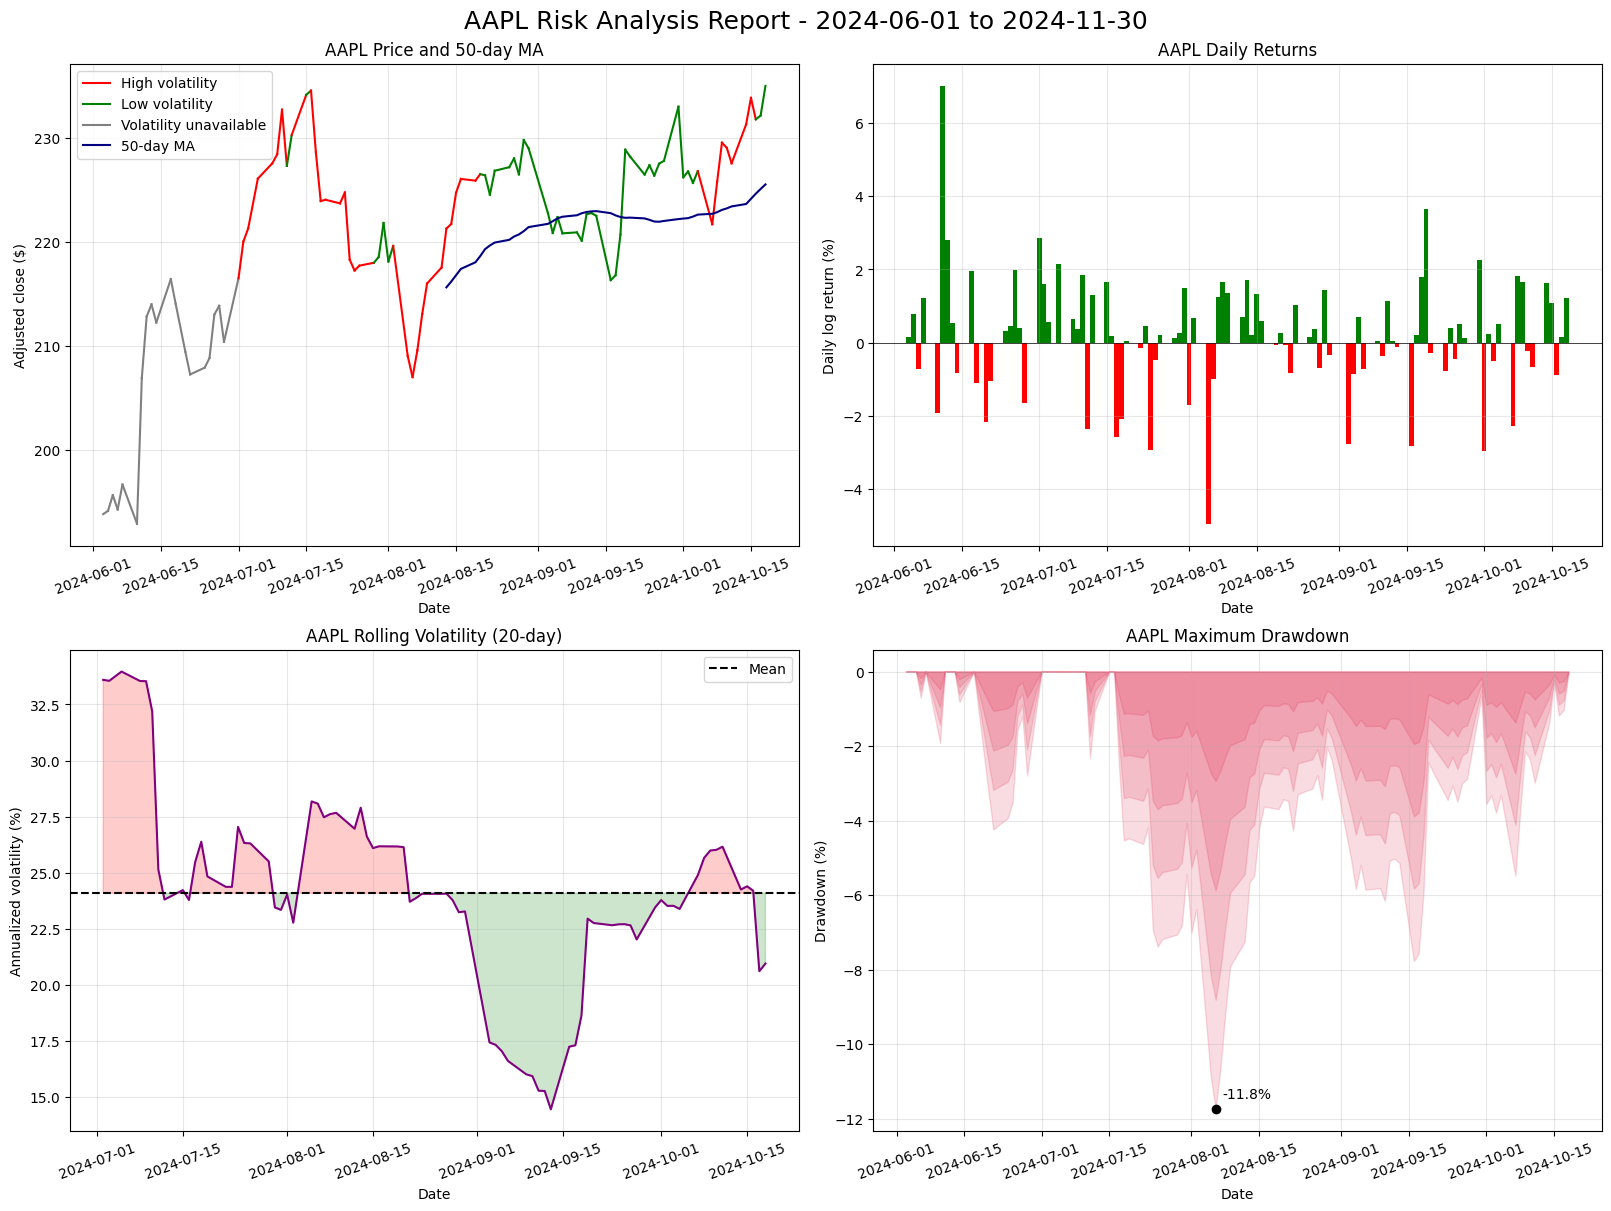

In [7]:
# Plot the four panels using adjusted prices and daily log returns.
from matplotlib.lines import Line2D
if stock.empty:
    raise ValueError(f"No observations for {ticker} in the requested date range.")
stock["ma_50d"] = stock["adj_close"].rolling(50).mean()
mean_volatility = stock["vol_20d"].mean()
fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout="constrained")
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=18)
# Price: color each segment by the rolling volatility at its ending date.
for i in range(1, len(stock)):
    vol = stock["vol_20d"].iloc[i]
    color = "gray" if pd.isna(vol) else ("red" if vol > mean_volatility else "green")
    axes[0, 0].plot(stock["ts"].iloc[i-1:i+1], stock["adj_close"].iloc[i-1:i+1],color=color, linewidth=1.5)
if len(stock) == 1:
    axes[0, 0].scatter(stock["ts"], stock["adj_close"], color="gray")
axes[0, 0].plot(stock["ts"], stock["ma_50d"], color="navy", label="50-day MA")
axes[0, 0].set(title=f"{ticker} Price and 50-day MA", ylabel="Adjusted close ($)")
axes[0, 0].legend(handles=[
    Line2D([], [], color="red", label="High volatility"),
    Line2D([], [], color="green", label="Low volatility"),
    Line2D([], [], color="gray", label="Volatility unavailable"),
    Line2D([], [], color="navy", label="50-day MA")
])
# Daily log returns: omit the first date, which has no return.
daily = stock.dropna(subset=["log_return"])
axes[0, 1].bar(daily["ts"], daily["log_return"] * 100, width=1,color=np.where(daily["log_return"] >= 0, "green", "red"))
axes[0, 1].axhline(0, color="black", linewidth=0.5)
axes[0, 1].set(title=f"{ticker} Daily Returns", ylabel="Daily log return (%)")
# Rolling volatility: shade the regions above and below its report-wide mean.
vol_pct = stock["vol_20d"] * 100
axes[1, 0].plot(stock["ts"], vol_pct, color="purple")
if pd.notna(mean_volatility):
    axes[1, 0].axhline(mean_volatility * 100, color="black", linestyle="--", label="Mean")
    for condition, color in [(stock["vol_20d"] > mean_volatility, "red"),
                             (stock["vol_20d"] <= mean_volatility, "green")]:
        axes[1, 0].fill_between(stock["ts"], vol_pct.to_numpy(), mean_volatility * 100,
                                where=condition.to_numpy(), color=color, alpha=0.2, interpolate=True)
    axes[1, 0].legend()
axes[1, 0].set(title=f"{ticker} Rolling Volatility (20-day)", ylabel="Annualized volatility (%)")
# Drawdown: layered transparent fills and the worst observation.
drawdown_pct = stock["drawdown"] * 100
for fraction in [1.0, 0.75, 0.5, 0.25]:
    axes[1, 1].fill_between(stock["ts"], drawdown_pct.to_numpy() * fraction,0, color="crimson", alpha=0.15)
worst = stock["drawdown"].idxmin()
axes[1, 1].scatter(stock.loc[worst, "ts"], drawdown_pct.loc[worst], color="black", zorder=3)
axes[1, 1].annotate(f"{drawdown_pct.loc[worst]:.1f}%",
                    (stock.loc[worst, "ts"], drawdown_pct.loc[worst]),
                    xytext=(5, 8), textcoords="offset points")
axes[1, 1].set(title=f"{ticker} Maximum Drawdown", ylabel="Drawdown (%)")
for ax in axes.flat:
    ax.set_xlabel("Date")
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", labelrotation=20)
plt.show()

### 2.5 Summary Statistics Table

In [8]:
# Calculate numeric summary statistics from adjusted prices and log returns.
returns = stock["log_return"].dropna()
n = len(returns)
stats = {
    "ticker": ticker,
    "trading_days": len(stock),
    "actual_start_date": stock["ts"].min().strftime("%Y-%m-%d"),
    "actual_end_date": stock["ts"].max().strftime("%Y-%m-%d"),
    "total_return": stock["adj_close"].iloc[-1] / stock["adj_close"].iloc[0] - 1 if n else np.nan,
    "annualized_return": np.expm1(returns.sum() * 252 / n) if n else np.nan,
    "annualized_volatility": returns.std() * np.sqrt(252),
    "avg_daily_return": returns.mean(),
    "avg_volatility": stock["vol_20d"].mean(),
    "sharpe_ratio": sharpe,
    "max_drawdown": stock["drawdown"].min(),
    "best_day": returns.max(),
    "worst_day": returns.min(),
    "positive_days": returns.gt(0).mean(),
    "average_up_day": returns.loc[returns > 0].mean(),
    "average_down_day": returns.loc[returns < 0].mean()
}
summary = pd.Series({
    "Total Return": stats["total_return"],
    "Annualized Return": stats["annualized_return"],
    "Annualized Volatility": stats["annualized_volatility"],
    "Sharpe Ratio": stats["sharpe_ratio"],
    "Maximum Drawdown": stats["max_drawdown"],
    "Best Day": stats["best_day"],
    "Worst Day": stats["worst_day"],
    "Positive Days": stats["positive_days"],
    "Average Up Day": stats["average_up_day"],
    "Average Down Day": stats["average_down_day"]
}, name="Value")
display_summary = pd.DataFrame({
    "Metric": summary.index,
    "Value": ["N/A" if pd.isna(value) else f"{value:.2f}" if metric == "Sharpe Ratio"
              else f"{value:.2%}" for metric, value in summary.items()]
})
display(display_summary)

,Metric,Value
0,Total Return,21.25%
1,Annualized Return,65.84%
2,Annualized Volatility,25.45%
3,Sharpe Ratio,1.91
4,Maximum Drawdown,-11.75%
5,Best Day,7.01%
6,Worst Day,-4.94%
7,Positive Days,62.50%
8,Average Up Day,1.09%
9,Average Down Day,-1.28%


In [9]:
# Make named results available to the Part 3 papermill script.
import scrapbook as sb
for name in ["avg_daily_return", "avg_volatility", "max_drawdown",
             "sharpe_ratio", "total_return"]:
    value = stats[name]
    sb.glue(name, None if pd.isna(value) else float(value))
for name in ["ticker", "trading_days", "actual_start_date", "actual_end_date"]:
    sb.glue(name, stats[name])
print("Summary metrics exported for batch analysis.")

Summary metrics exported for batch analysis.
